# Delaunay-Watershed in 2D: geometrical analysis

This notebook meshes a 2-D segmentation mask with dw2d and reads the geometry of the cells from the mesh: the length of every interface, the angles at every junction, the curvature of every interface and the area of every cell.

Run it from its folder, `Examples/two_dimensional/`, with `delaunay-watershed[viewing]` installed (matplotlib, for the figures).

## 1) Mesh the mask

In [1]:
import tifffile

import dw2d

image = tifffile.imread("../../data/two_dimensional/BW_images/CellCells_3.tif")
mask = tifffile.imread("../../data/two_dimensional/Masks/mask_Cells_3.tif")
print("image", image.shape, image.dtype, "| mask", mask.shape, mask.dtype, "labels", sorted(set(mask.ravel().tolist())))

algorithm = dw2d.get_default_mesh_reconstruction_algorithm()  # min_distance=4 pixels, every 0.8.0 default
points, segments, labels = algorithm.construct_mesh_from_segmentation_mask(mask)
print(f"{len(points)} points (n, 2) in (row, column) pixels, {len(segments)} edges, labels {labels.shape}")
print(algorithm.relocation_report)

image (182, 190) uint8 | mask (182, 190) int32 labels [0, 1, 2, 4]
338 points (n, 2) in (row, column) pixels, 114 edges, labels (114, 2)
JunctionRelocationReport(mask_junctions=4, mesh_junctions=4, planned=4, fixed=0, moved=4, refused={}, unmatched_triples=0, crossings_before=0, crossings_after=0, contacts_before=0, contacts_after=0, median_displacement_px=0.7071067811865476)


`points` are in the mask's `(row, column)` order; each row of `labels` gives the two materials an edge separates, smaller first, and the first lies on the left of the edge `segments[k, 0] -> segments[k, 1]` in `(row, column)`. The junction relocation, on by default, moved the junction vertices onto the corners where three labels meet in the mask (`relocation_report`).

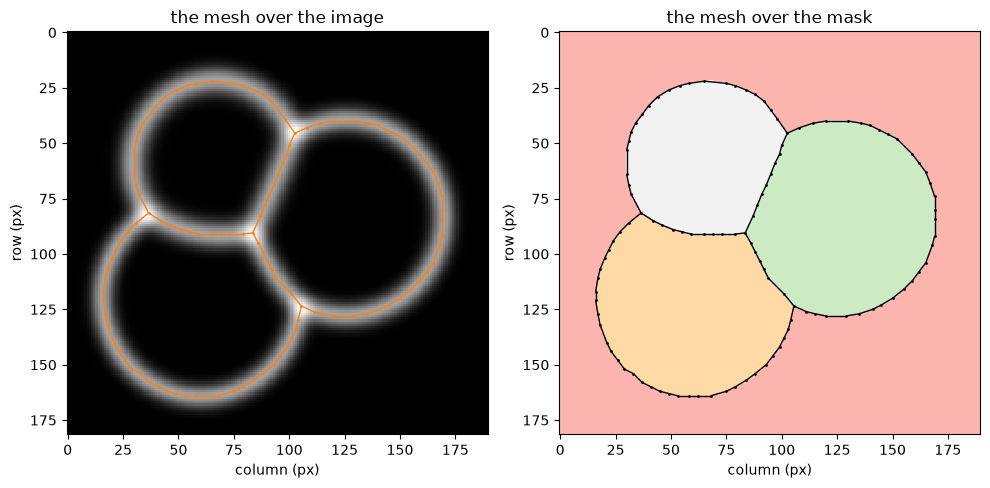

In [2]:
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.collections import LineCollection


def draw_mesh(ax, background, points, segments, colour="tab:orange", cmap="gray"):
    """Draw a 2-D mesh over an image, as imshow shows the image: column to the right, row down."""
    ax.imshow(background, cmap=cmap, interpolation="nearest")
    xy = points[:, ::-1]  # the mesh is in (row, column); matplotlib draws (x, y) = (column, row)
    ax.add_collection(LineCollection(xy[segments], colors=colour, linewidths=1))
    used = np.unique(segments)
    ax.plot(xy[used, 0], xy[used, 1], ".", color=colour, markersize=2)
    ax.set_xlabel("column (px)")
    ax.set_ylabel("row (px)")


fig, axes = plt.subplots(1, 2, figsize=(10, 5))
draw_mesh(axes[0], image, points, segments)
axes[0].set_title("the mesh over the image")
draw_mesh(axes[1], mask, points, segments, colour="black", cmap="Pastel1")
axes[1].set_title("the mesh over the mask")
plt.tight_layout()
plt.show()

## 2) The half-edge structure and the geometry

`last_constructed_dcel` is the half-edge structure of the mesh. Each quantity is a dictionary keyed by the materials (0 is the medium): interfaces by their two materials, junctions by their three.

In [3]:
mesh = algorithm.last_constructed_dcel

print("interface lengths (px)")
for (a, b), length in mesh.compute_lengths().items():
    print(f"  {int(a)}-{int(b)}: {length:.1f}")

interface lengths (px)
  0-1: 183.4
  0-2: 181.5
  0-4: 127.6
  1-2: 40.0
  1-4: 48.9
  2-4: 49.2


In [4]:
print("junction angles (degrees): (a, b, c) is the angle inside material b between its interfaces with a and c")
for (a, b, c), angle in mesh.compute_angles().items():
    if a < c:  # each angle is listed under (a, b, c) and (c, b, a)
        print(f"  ({int(a)}, {int(b)}, {int(c)}): {np.degrees(angle):.1f}")

junction angles (degrees): (a, b, c) is the angle inside material b between its interfaces with a and c
  (0, 1, 2): 153.7
  (0, 2, 4): 108.2
  (0, 4, 1): 120.9
  (1, 0, 4): 100.3
  (1, 4, 2): 121.4
  (2, 1, 4): 125.9
  (0, 2, 1): 127.7
  (1, 0, 2): 78.6
  (0, 4, 2): 150.4
  (2, 0, 4): 101.4
  (0, 1, 4): 138.9
  (1, 2, 4): 112.7


In [5]:
print("interface curvatures (1/px, unsigned): the length-weighted mean of the Menger curvature, junctions excluded")
for (a, b), curvature in mesh.compute_curvatures().items():
    print(f"  {int(a)}-{int(b)}: {curvature:.4f}  (radius {1 / curvature:.0f} px)")

interface curvatures (1/px, unsigned): the length-weighted mean of the Menger curvature, junctions excluded
  0-1: 0.0225  (radius 44 px)
  0-2: 0.0254  (radius 39 px)
  0-4: 0.0254  (radius 39 px)
  1-2: 0.0136  (radius 73 px)
  1-4: 0.0169  (radius 59 px)
  2-4: 0.0155  (radius 64 px)


In [6]:
print("cell areas (square px), against their pixel counts")
for material, area in mesh.compute_area_faces().items():
    if material == 0:
        continue  # the medium's entry is the signed area enclosed by the tissue's outer boundary
    print(f"  cell {int(material)}: {area:.0f} (mask: {(mask == material).sum()} pixels)")

cell areas (square px), against their pixel counts
  cell 1: 5719 (mask: 5749 pixels)
  cell 2: 5320 (mask: 5332 pixels)
  cell 4: 3862 (mask: 3876 pixels)


Each interface drawn in the colour of its curvature, over the mask:

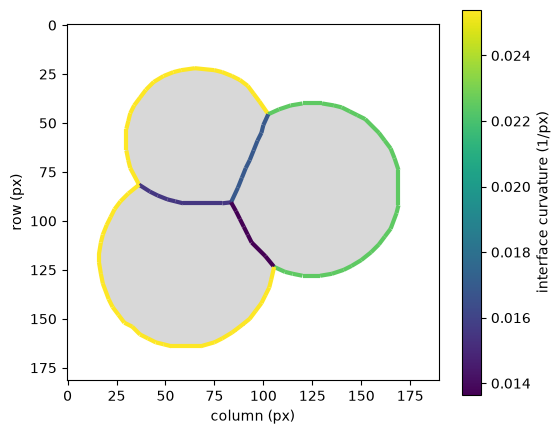

In [7]:
curvatures = {tuple(int(m) for m in key): value for key, value in mesh.compute_curvatures().items()}
pairs = [tuple(int(m) for m in pair) for pair in labels]
values = np.array([curvatures.get(pair, np.nan) for pair in pairs])
xy = points[:, ::-1]
fig, ax = plt.subplots(figsize=(6, 5))
ax.imshow(mask > 0, cmap="Greys", vmin=0, vmax=4, interpolation="nearest")
lines = LineCollection(xy[segments], array=values, cmap="viridis", linewidths=3)
ax.add_collection(lines)
fig.colorbar(lines, ax=ax, label="interface curvature (1/px)")
ax.set_xlabel("column (px)")
ax.set_ylabel("row (px)")
plt.show()

`plot_local_curvature` draws the curvature along each cell's boundary, edge by edge, on the pixel grid: each edge takes the mean of the Menger curvature at its two vertices (1/px, unsigned; at a junction vertex the curvature mixes two interfaces), the values clipped to their 5th and 95th percentiles. Where two cells share an edge, the cell drawn last gives its colour.

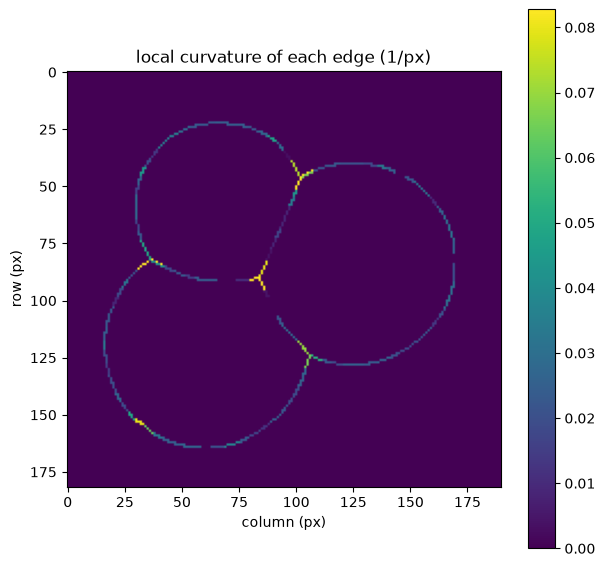

In [8]:
mesh.plot_local_curvature(mask)  # an image of the mask's shape, edges drawn by their pixels
plt.title("local curvature of each edge (1/px)")
plt.xlabel("column (px)")
plt.ylabel("row (px)")
plt.show()

## 3) Save the mesh and read it back

`save_to_rec_mesh` writes a `.rec` file (text by default) with a metadata appendix that records `dimension = 2`, the axis order, the image-border vertices and the orientation rule of the edges. `dw2d.io.load_rec` returns the same three arrays.

In [9]:
import dw2d.io
from dw3d.io import rec_dimension

algorithm.save_to_rec_mesh("mesh_2d.rec")
points_read, segments_read, labels_read = dw2d.io.load_rec("mesh_2d.rec")
print("dimension recorded:", rec_dimension("mesh_2d.rec"))
print("same arrays:", np.array_equal(points_read, points), np.array_equal(segments_read, segments), np.array_equal(labels_read, labels))
print(dw2d.io.load_rec_appendix("mesh_2d.rec"))

dimension recorded: 2
same arrays: True True True
{'_version': 1, 'written_by': '0.8.0.dev0', 'writer_library': 'iorec 1.4.1', 'dimension': 2, 'axis_order': 'yx', 'orientation': 'boundary_of_first_label', 'source_shape': (182, 190), 'image_border_vertices': (0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 34, 35, 36, 37, 38, 39, 40, 41, 42, 43, 44, 45, 46, 47, 48, 49, 50, 51, 52, 53, 54, 55, 56, 57, 59, 60, 61, 62, 63, 64, 65, 66, 67, 68, 69, 70, 72, 73, 74, 75, 76, 77, 78, 79, 80, 81, 82, 83, 84, 85, 86, 87, 88, 89, 91, 92, 93, 94, 96, 97, 98, 99, 100, 101, 102, 103, 104, 105, 106, 107, 108, 109, 110, 111, 112, 114, 115, 116, 117, 118, 119, 120, 121, 122, 123, 124, 125, 126, 127, 128, 129, 130, 131, 132, 133, 134, 135, 136, 137, 138, 139, 140, 141, 142, 143, 144, 145, 146, 147, 148, 149, 150, 151, 152, 153, 154, 155, 156, 157, 158, 159, 160, 161, 162, 163, 164, 165, 166, 167, 168, 169, 170, 171, 172, 173, 17

## 4) The same mesh from dw3d's algorithm

dw3d's reconstruction algorithm hands a 2-D mask to dw2d: the same call meshes a 2-D or a 3-D mask, and gives the same arrays.

In [10]:
from dw3d import get_default_mesh_reconstruction_algorithm

points_3d_api, segments_3d_api, labels_3d_api = get_default_mesh_reconstruction_algorithm().construct_mesh_from_segmentation_mask(mask)
print("the same mesh:", np.array_equal(points_3d_api, points), np.array_equal(segments_3d_api, segments), np.array_equal(labels_3d_api, labels))

the same mesh: True True True
